In [61]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt
import py_files.config as cfg
import inspect

from py_files.functions import (
                       get_tau_array,
                       get_covariation_matrix,
                       get_channel_matrix,
                       get_barlet_values,
                       get_sin_signal,
                       get_impulse_signal, get_noise, 
                       calculate_noise_level, 
                       calculate_energy,
                       get_avp_signals, 
                       get_direction_matrix, 
                       get_est_phi,
                       get_cap_values,
                       calculate_freq_spectr, calculate_99,
                       calculate_f_rms)

config_parametrs = cfg.init_rng()

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [62]:
sin_signal = get_sin_signal(config_parametrs)
pulse_signal = get_impulse_signal(config_parametrs)
en_signal = calculate_energy(pulse_signal, config_parametrs["time_vector"])


In [63]:
freq_signal = calculate_freq_spectr(pulse_signal, cfg.FS)
B = calculate_f_rms(freq_signal, config_parametrs)
eff_B = 2*B

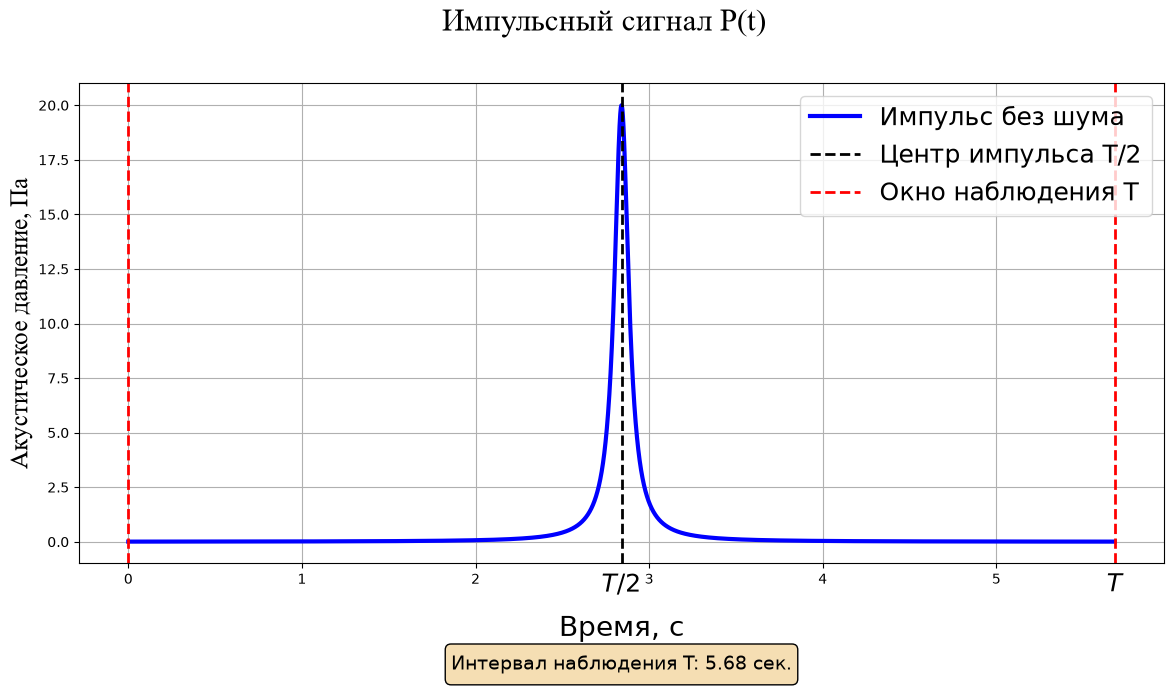

In [64]:


# Построение графика
title_main = "Импульсный сигнал P(t)"
fig, ax = plt.subplots(1, 1, figsize=(14, 8))
fig.subplots_adjust(top=0.85, bottom=0.25)


ax.plot(
    cfg.TIME_VECTOR, pulse_signal,
    color="blue", linewidth=3, label="Импульс без шума"
)

# Названия осей и заголовок
ax.set_xlabel("Время, с", labelpad=20, fontsize=20)
ax.set_ylabel("Акустическое давление, Па", fontsize=18, fontfamily="Times New Roman")

fig.suptitle(
    title_main,
    y=0.925, va="center",
    fontfamily="Times New Roman", fontsize=22
)

# Центр импульса и отметки времени
ax.axvline(
    config_parametrs["center_pulse"],
    color="black", linestyle="--", linewidth=2,
    label="Центр импульса T/2"
)
ax.axvline(
    0,
    color="red", linestyle="--", linewidth=2,
)
ax.axvline(
    config_parametrs["duration_all"],
    color="red", linestyle="--", linewidth=2,
    label="Окно наблюдения T"
)
ax.text(
    config_parametrs["center_pulse"], -0.02, r"$T/2$",
    transform=ax.get_xaxis_transform(),
    ha="center", va="top", fontsize=18
)
ax.text(
    config_parametrs["duration_all"], -0.02, r"$T$",
    transform=ax.get_xaxis_transform(),
    ha="center", va="top", fontsize=18
)

ax.grid(True)
ax.legend(loc="upper right", fontsize=18)

# Параметры под графиком
info = (

    f"Интервал наблюдения T: {config_parametrs['duration_all']:.2f} сек."
    
)

ax.text(
    0.5, -0.18, info,
    transform=ax.transAxes,
    fontsize=14, linespacing=1.5,
    ha="center", va="top",
    bbox=dict(boxstyle="round", facecolor="wheat", alpha=1),
    clip_on=False
)
plt.savefig(fname = f"images/notebook/{title_main}", bbox_inches = 'tight', dpi = 300)
plt.show()

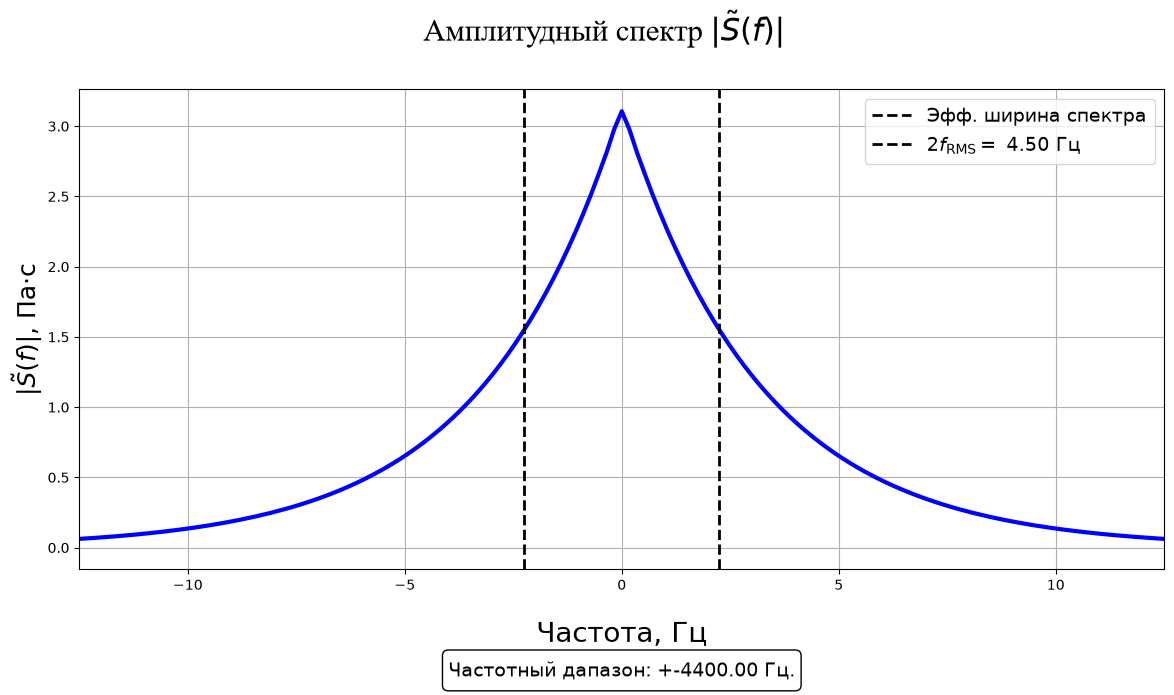

In [65]:


# Построение графика
title_main = "Амплитудный спектр S(f)"
fig, ax = plt.subplots(1, 1, figsize=(14, 8))
fig.subplots_adjust(top=0.85, bottom=0.25)


ax.plot(
    cfg.FREQ_VECTOR, freq_signal,
    color="blue", linewidth=3
)

# Названия осей и заголовок
ax.set_xlabel("Частота, Гц", labelpad=20, fontsize=20)
ax.set_ylabel(r"$|\tilde{S}(f)|$, Па·с", fontsize=18)
fig.suptitle(
    r"Амплитудный спектр $|\tilde{S}(f)|$",
    y=0.925, va="center",
    fontfamily="Times New Roman", fontsize=22
)

# Центр импульса и отметки времени


ax.axvline(
    -B,
    color="black", linestyle="--", linewidth=2,
    label="Эфф. ширина спектра"
)

ax.axvline(
    B,
    color="black", linestyle="--", linewidth=2,
    label=r"$2f_\text{RMS} = $" + f" {2*B:.2f} Гц"
)

ax.legend(loc="upper right", fontsize=14)

# Параметры под графиком
info = (

    f"Частотный дапазон: +-{config_parametrs['fs']/2:.2f} Гц."
    
)
ax.set_xlim(-12.5,12.5)
ax.text(
    0.5, -0.18, info,
    transform=ax.transAxes,
    fontsize=14, linespacing=1.5,
    ha="center", va="top",
    bbox=dict(boxstyle="round", facecolor="none", alpha=1),
    clip_on=False
)
ax.grid(True)
plt.savefig(fname = f"images/notebook/{title_main}", bbox_inches = 'tight', dpi = 300)
plt.show()

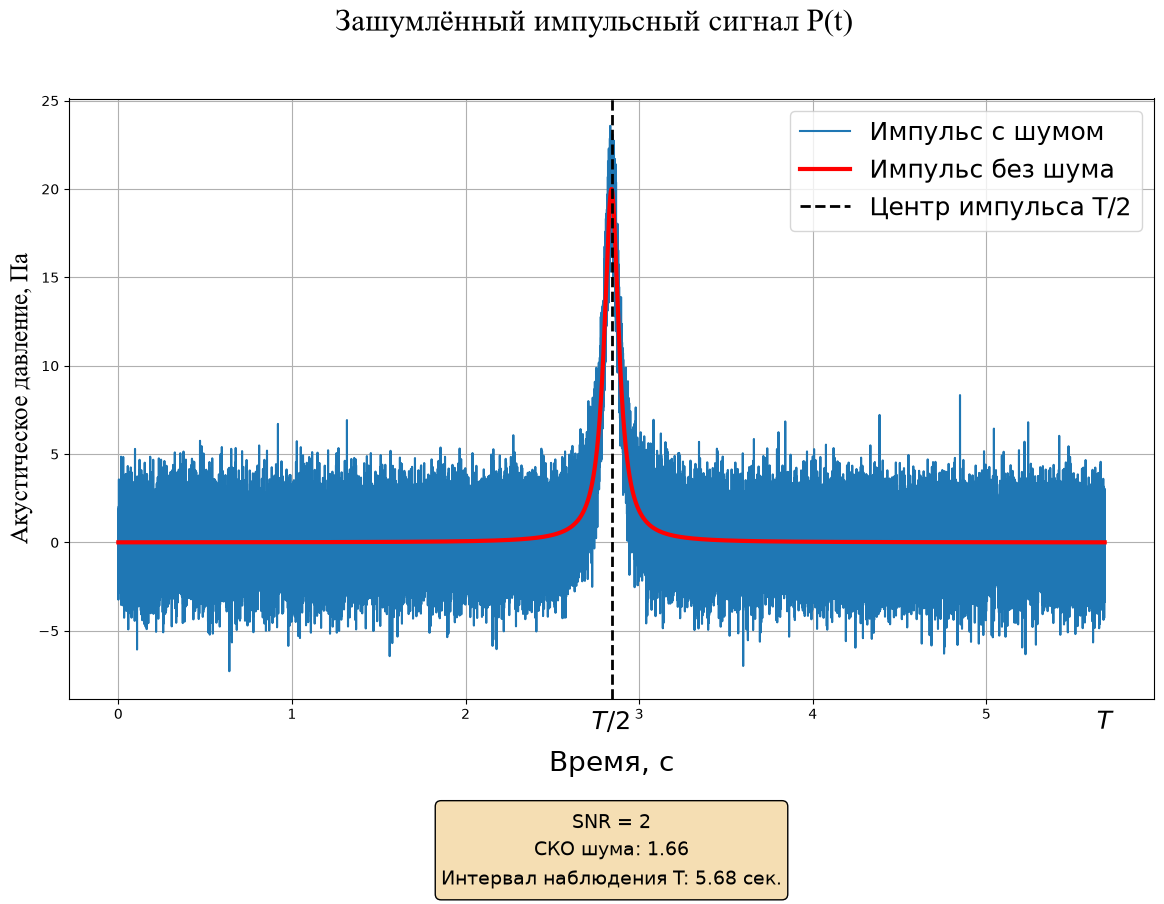

In [66]:
# Построение графика

title_main = "Зашумлённый импульсный сигнал P(t)"

noise = get_noise(config_parametrs, np.random.default_rng(42),en_signal)
noise_level = calculate_noise_level(en_signal, config_parametrs["snr"], config_parametrs["duration_all"])

noise_signal = pulse_signal + noise
fig, ax = plt.subplots(1, 1, figsize=(14, 10))
fig.subplots_adjust(top=0.85, bottom=0.25)

ax.plot(cfg.TIME_VECTOR, noise_signal, label="Импульс с шумом")
ax.plot(
    cfg.TIME_VECTOR, pulse_signal,
    color="red", linewidth=3, label="Импульс без шума"
)

# Названия осей и заголовок
ax.set_xlabel("Время, с", labelpad=20, fontsize=20)
ax.set_ylabel("Акустическое давление, Па", fontsize=18, fontfamily="Times New Roman")

fig.suptitle(
    title_main,
    y=0.925, va="center",
    fontfamily="Times New Roman", fontsize=22
)

# Центр импульса и отметки времени
ax.axvline(
    config_parametrs["center_pulse"],
    color="black", linestyle="--", linewidth=2,
    label="Центр импульса T/2"
)

ax.text(
    config_parametrs["center_pulse"], -0.02, r"$T/2$",
    transform=ax.get_xaxis_transform(),
    ha="center", va="top", fontsize=18
)
ax.text(
    config_parametrs["duration_all"], -0.02, r"$T$",
    transform=ax.get_xaxis_transform(),
    ha="center", va="top", fontsize=18
)

ax.grid(True)
ax.legend(loc="upper right", fontsize=18)

# Параметры под графиком
info = (
    f"SNR = {cfg.SNR}\n"
    f"СКО шума: {noise_level:.2f}\n"
    f"Интервал наблюдения T: {config_parametrs['duration_all']:.2f} сек."
    
)

ax.text(
    0.5, -0.18, info,
    transform=ax.transAxes,
    fontsize=14, linespacing=1.5,
    ha="center", va="top",
    bbox=dict(boxstyle="round", facecolor="wheat", alpha=1),
    clip_on=False
)
plt.savefig(fname = f"images/notebook/{title_main}", bbox_inches = 'tight', dpi = 300)
plt.show()

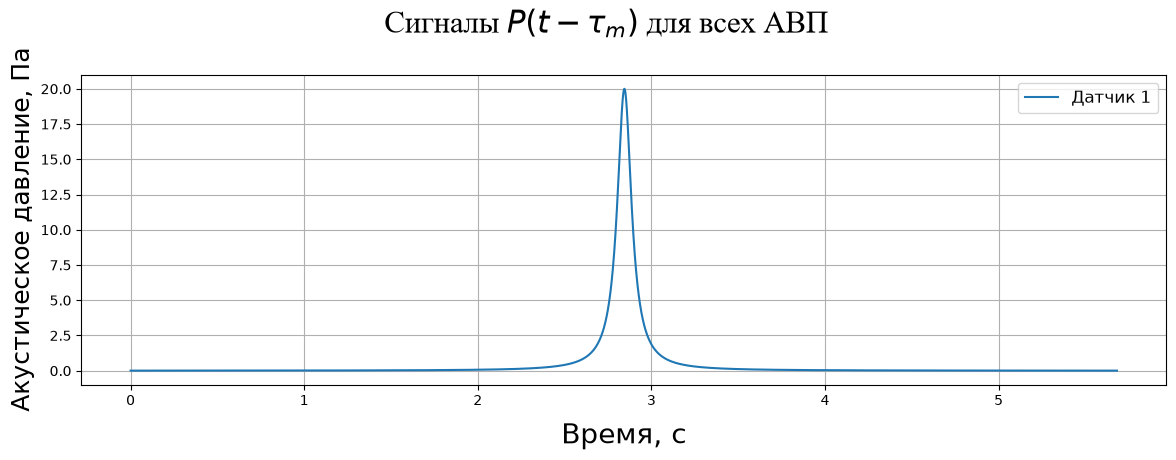

In [67]:
tau_array = get_tau_array(config_parametrs)
params_vector_copy = config_parametrs.copy()

fig, ax = plt.subplots(1, 1, figsize=(14, 5))
fig.subplots_adjust(top=0.80, bottom=0.18)

# Сигнал на каждом датчике
for idx, tau in enumerate(tau_array):
    params_vector_copy["time_vector"] = config_parametrs["time_vector"] - tau
    signal = get_impulse_signal(params_vector_copy)

    ax.plot(
        config_parametrs["time_vector"], signal,
        label=f"Датчик {idx + 1}"
    )

# Названия осей и заголовок
ax.set_xlabel("Время, с", labelpad=10, fontsize=20)
ax.set_ylabel("Акустическое давление, Па", fontsize=18)
fig.suptitle(
    r"Сигналы $P(t-\tau_m)$ для всех АВП",
    y=0.90, va="center",
    fontfamily="Times New Roman", fontsize=22
)

ax.grid(True)
ax.legend(loc="upper right", fontsize=12)

plt.show()

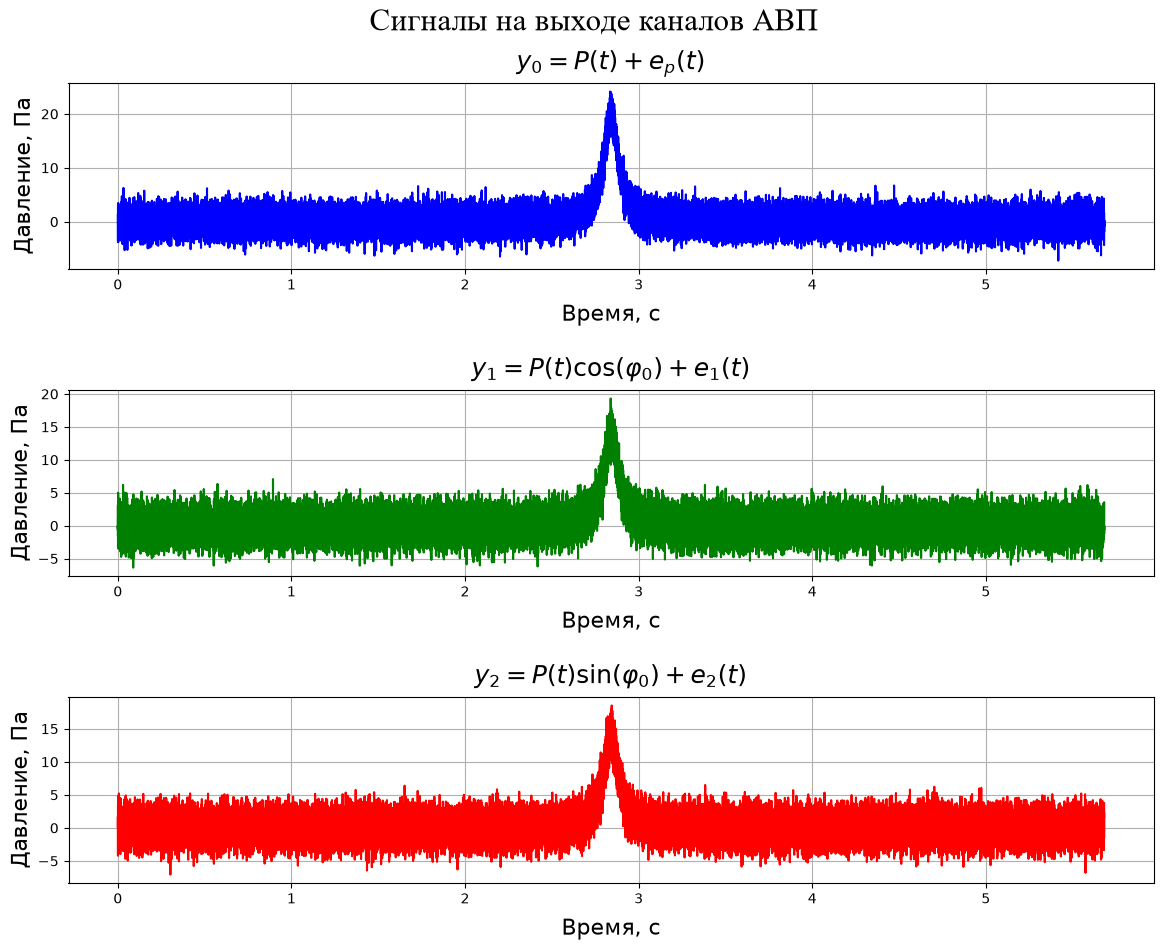

In [68]:
cfg.init_rng()
title_main = r"Сигналы на выходе каналов АВП"
signals = get_avp_signals(pulse_signal, config_parametrs, en_signal)

fig, axs = plt.subplots(3, 1, figsize=(14, 10))
fig.subplots_adjust(top=0.88, bottom=0.08, hspace=0.65)

fig.suptitle(
    title_main,
    y=0.94, va="center",
    fontfamily="Times New Roman", fontsize=22
)

colors = ("blue", "green", "red")
titles = (
    r"$y_0 = P(t) + e_p(t)$",
    r"$y_1 = P(t)\cos(\varphi_0) + e_1(t)$",
    r"$y_2 = P(t)\sin(\varphi_0) + e_2(t)$"
)

for ax, y, title, color in zip(axs, signals.values(), titles, colors):
    ax.plot(cfg.TIME_VECTOR, y, color=color)
    ax.set_xlabel("Время, с", labelpad=8, fontsize=16)
    ax.set_ylabel("Давление, Па", fontsize=16)
    ax.set_title(title, pad=10, fontsize=18)
    ax.grid(True)
    
plt.savefig(fname = f"images/notebook/{str(title_main)}", bbox_inches = 'tight', dpi = 300)
plt.show()

In [69]:
channel_matrix = get_channel_matrix(config_parametrs, tau_array, get_impulse_signal)
W = get_covariation_matrix(channel_matrix, cfg.N)
dir_matrix = get_direction_matrix(cfg.PHI_VECTOR, cfg.M)
E_bar = get_barlet_values(W,dir_matrix)
E_cap = get_cap_values(W, dir_matrix)


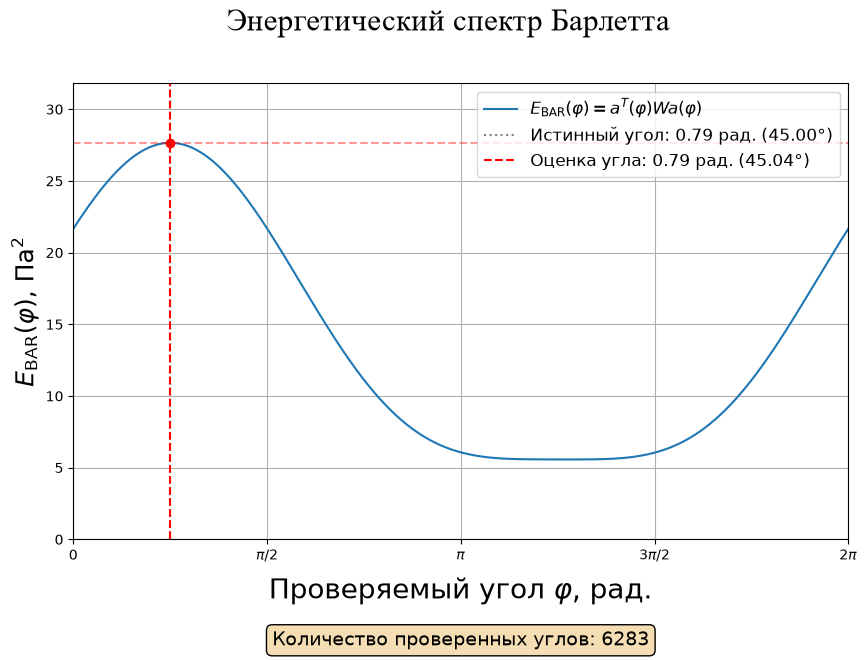

In [70]:

title_main = "Энергетический спектр Барлетта"

sigma_noise = noise_level
phi_0 = cfg.TARGET_PHI
phi_vector = cfg.PHI_VECTOR
A = cfg.A

est_phi = get_est_phi(phi_vector, E_bar)
E_max = max(E_bar)

snr_ratio = np.inf if sigma_noise == 0 else A**2 / sigma_noise**2
snr_text = (
    "∞ (без шума)" if np.isinf(snr_ratio)
    else f"{snr_ratio:.2f} ({10 * np.log10(snr_ratio):.2f} дБ)"
)

fig, ax = plt.subplots(figsize=(10, 8))
fig.subplots_adjust(top=0.85, bottom=0.28)

# Функция Бартлетта и отметки углов
ax.plot(
    phi_vector, E_bar,
    label=r"$E_{\mathrm{BAR}}(\varphi)=a^T(\varphi)W a(\varphi)$"
)


ax.axvline(
    phi_0, color="gray", linestyle=":",
    label=f"Истинный угол: {phi_0:.2f} рад. ({np.degrees(phi_0):.2f}°)"
)
ax.axvline(
    est_phi, color="red", linestyle="--",
    label=f"Оценка угла: {est_phi:.2f} рад. ({np.degrees(est_phi):.2f}°)"
)

ax.scatter(est_phi, E_max, color="red", zorder=3)
ax.axhline(E_max, color="red", linestyle="--", alpha=0.4)

# Названия осей и заголовок
fig.suptitle(
    title_main,
    y=0.925, va="center",
    fontfamily="Times New Roman", fontsize=22
)

ax.set_xlabel(r"Проверяемый угол $\varphi$, рад.", labelpad=10, fontsize=20)
ax.set_ylabel(r"$E_{\mathrm{BAR}}(\varphi)$, Па$^2$", fontsize=18)

ax.set_xticks(
    [0, np.pi / 2, np.pi, 3 * np.pi / 2, 2 * np.pi],
    ["0", r"$\pi/2$", r"$\pi$", r"$3\pi/2$", r"$2\pi$"]
)

ax.set_xlim(0, 2 * np.pi)
ax.set_ylim(0, 1.15 * E_max)
ax.legend(loc="upper right", fontsize=12)
ax.grid(True)



# Количество углов в сетке поиска
info = f"Количество проверенных углов: {len(phi_vector)}"
ax.text(
    0.5, -0.20, info,
    transform=ax.transAxes,
    fontsize=14,
    ha="center", va="top",
    bbox=dict(boxstyle="round", facecolor="wheat", alpha=1),
    clip_on=False
)
plt.savefig(fname = f"images/notebook/{title_main}", bbox_inches = 'tight', dpi = 300)
plt.show()

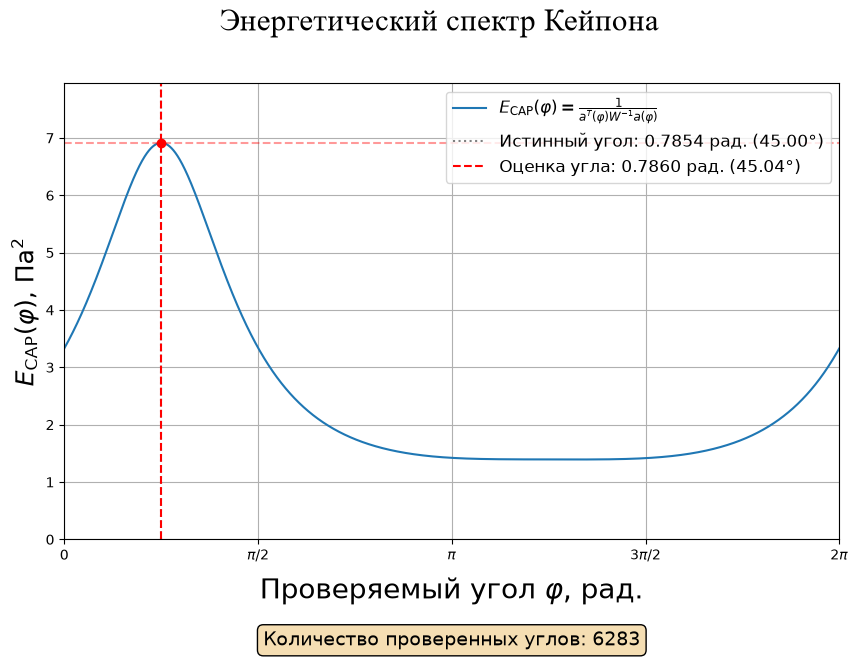

In [71]:
title_main = "Энергетический спектр Кейпона"

sigma_noise = noise_level
phi_0 = cfg.TARGET_PHI
phi_vector = cfg.PHI_VECTOR
A = cfg.A

est_phi = get_est_phi(phi_vector, E_cap)
E_max = max(E_cap)

snr_ratio = np.inf if sigma_noise == 0 else A**2 / sigma_noise**2
snr_text = (
    "∞ (без шума)" if np.isinf(snr_ratio)
    else f"{snr_ratio:.2f} ({10 * np.log10(snr_ratio):.2f} дБ)"
)

fig, ax = plt.subplots(figsize=(10, 8))
fig.subplots_adjust(top=0.85, bottom=0.28)

# Функция Кейпона и отметки углов
ax.plot(
    phi_vector, E_cap,
    label=r"$E_{\mathrm{CAP}}(\varphi)=\frac{1}{a^T(\varphi)W^{-1}a(\varphi)}$"
)


ax.axvline(
    phi_0, color="gray", linestyle=":",
    label=f"Истинный угол: {phi_0:.4f} рад. ({np.degrees(phi_0):.2f}°)"
)
ax.axvline(
    est_phi, color="red", linestyle="--",
    label=f"Оценка угла: {est_phi:.4f} рад. ({np.degrees(est_phi):.2f}°)"
)

ax.scatter(est_phi, E_max, color="red", zorder=3)
ax.axhline(E_max, color="red", linestyle="--", alpha=0.4)

# Названия осей и заголовок
fig.suptitle(
    "Энергетический спектр Кейпона",
    y=0.925, va="center",
    fontfamily="Times New Roman", fontsize=22
)

ax.set_xlabel(r"Проверяемый угол $\varphi$, рад.", labelpad=10, fontsize=20)
ax.set_ylabel(r"$E_{\mathrm{CAP}}(\varphi)$, Па$^2$", fontsize=18)

ax.set_xticks(
    [0, np.pi / 2, np.pi, 3 * np.pi / 2, 2 * np.pi],
    ["0", r"$\pi/2$", r"$\pi$", r"$3\pi/2$", r"$2\pi$"]
)

ax.set_xlim(0, 2 * np.pi)
ax.set_ylim(0, 1.15 * E_max)
ax.legend(loc="upper right", fontsize=12)
ax.grid(True)



# Количество углов в сетке поиска
info = f"Количество проверенных углов: {len(phi_vector)}"
ax.text(
    0.5, -0.20, info,
    transform=ax.transAxes,
    fontsize=14,
    ha="center", va="top",
    bbox=dict(boxstyle="round", facecolor="wheat", alpha=1),
    clip_on=False
)
plt.savefig(fname = f"images/notebook/{title_main}", bbox_inches = 'tight', dpi = 300)
plt.show()